# Figure 6 -- nine periodograms, placed on the map (`characterizability_examples_kepmodel_3class`)

**Left:** the one-companion population in companion mass vs. orbital period, every companion
coloured by the same three-class periodogram classification as Figure 7, with nine of them ringed
and lettered. **Right:** the `kepmodel` periodogram of each, three per class and one class per row,
titled with the system's injected parameters and marked with the injected period, the mission
baseline and the null-calibrated detection threshold.

Nothing is refitted: each curve is the $\Delta\chi^2$ the catalog's period search returns for that
system, re-run here from its epochs with the generator package's own `kepmodel_power` on the run's
own trial grid (checked against `period_grid.parquet`), and the row it sits in is the class the
classification assigns from that same curve. The epochs are read off the catalog server one system
at a time (`paperfig.fetch_epochs`), so the 28 GB of epoch shards are not needed locally.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

import paperfig as pf          # paths, style, loaders and the shared figure machinery

pf.setup_style()               # Computer Modern, usetex -- the paper's typography
print("catalog :", pf.CATALOG)
print("paper figures         :", pf.PAPER_FIG_DIR)
print("supplementary figures :", pf.SUPP_FIG_DIR)

catalog : /Users/daniel/Desktop/epochalypse_catalog/catalog
paper figures         : /Users/daniel/Desktop/epochalypse_catalog/analysis/paper_figures
supplementary figures : /Users/daniel/Desktop/epochalypse_catalog/analysis/supplementary_figures


## 1. The one-companion characterization table, and the run's own search

In [2]:
MAN, CAL = pf.manifest(), pf.calibration()
thr_orbit, thr_accel = CAL["thr_orbit"], CAL["thr_accel"]
print(f"thresholds (FP = {CAL['target_fp']:.0%} on {CAL['n_null_systems']:,} control systems): "
      f"orbit Delta-chi2 > {thr_orbit:.1f}, accel > {thr_accel:.1f}; realized {CAL['realized_fp']:.3%}")

POP = "1_companion"
chars = pf.load_chars(POP)
DET = "detected_cal"
CLF = lambda df, k: pf.classes(df, k, det_col=DET)

# the search the catalog was characterized with: the grid is asserted against the manifest
# and against period_grid.parquet before any curve is drawn
PERIODS, PGRAM = pf.kepmodel_search()
print(f"kepmodel search: {PERIODS[0]:.2e} -> {PERIODS[-1]:.0f} yr, {len(PERIODS):,} trial periods "
      f"over {MAN['grid']['n_segments']} segments")
AX_P = pf.period_axis()

thresholds (FP = 1% on 5,040,328 control systems): orbit Delta-chi2 > 88.4, accel > 18.9; realized 0.890%


  1_companion            5,040,328 systems   characterization_1_companion.parquet
kepmodel search: 1.30e-03 -> 3700 yr, 15,777 trial periods over 32 segments


## 2. The subsample the map draws, and the nine examples

The map is the paper's shared 10,000-system subsample of the population (the same stars every
other figure draws); the examples are picked from it. `ANCHORS` says where to look --
`{class: [(period, mass[, required flags]), ...]}` -- and the nearest system of that class in the
log-log plane is taken. Two of the three *not localized* panels are pinned to a significant
periodogram peak and the third to the acceleration channel alone, so the row shows both ways a
system ends up significant but not localized. The *localized* anchors sit at 1--3 yr: a peak is
$\sim P/T$ of a natural log wide, so on a 6.5-decade axis a shorter-period peak reads as a vertical
line, while past $\sim 3.5$ yr the long-period plateau rises to within a factor 1.6 of the peak and
a localized system no longer *looks* localized.

In [3]:
N_MAP = 10_000
MAP_DRAW = pf.draw(chars, N_MAP)
_full, _sub = CLF(chars, 1), CLF(MAP_DRAW, 1)
print("class fractions [% of companions]   full population  /  10,000-system subsample")
for key in pf.LEGEND_ORDER:
    print(f"  {pf.SHORT_3[key]:55s} {100 * np.mean(_full == key):5.1f}%  /  {100 * np.mean(_sub == key):5.1f}%")

ANCHORS = {
    "narrow": [(2.43, 15.8), (1.4, 5.0), (2.59, 42.1)],
    "broad": [(7.0, 10.0, {"peak_significant_cal": True}),
              (25.0, 30.0, {"peak_significant_cal": True}),
              (400.0, 60.0, {"peak_significant_cal": False, "accel_significant_cal": True})],
    "undet": [(0.1, 0.01), (3.0, 0.5), (500.0, 20.0)],
}
picks = pf.select_examples(MAP_DRAW, ANCHORS, classify=CLF)
picks["Mp_1_mjup"] = picks["Mp_1_msun"] / pf.MJUP
picks[["tag", "cls", "gaia_source_id", "shard", "period_1", "Mp_1_mjup", "alpha_1_mas",
       "snr_total_1", "top_power", "accel_delta_chi2", "width_dex", "klass",
       "peak_significant_cal", "accel_significant_cal"]]

class fractions [% of companions]   full population  /  10,000-system subsample
  no significant peak or acceleration                      93.8%  /   93.5%
  significant peak, period localized                        2.3%  /    2.4%
  significant peak or acceleration, period not localized    3.9%  /    4.2%


,tag,cls,gaia_source_id,shard,period_1,Mp_1_mjup,alpha_1_mas,snr_total_1,top_power,accel_delta_chi2,width_dex,klass,peak_significant_cal,accel_significant_cal
0,A,narrow,4655026950041457536,204,2.478776,15.326101,0.171277,28.699355,747.771044,69.724677,0.016982,unimodal,True,True
1,B,narrow,6340070713349433856,163,1.121670,6.626642,0.125075,18.513877,409.272697,1.301155,0.009200,unimodal,True,False
2,C,narrow,602247568446231936,135,2.619981,39.845617,0.115808,15.173657,293.232779,88.444112,0.032050,unimodal,True,True
3,D,broad,5480103189928118144,19,7.066059,11.783247,0.175454,13.895958,321.492335,282.020562,0.273780,broad,True,True
4,E,broad,3415503442849782528,154,25.197729,33.214558,23.214464,197.411894,11363.955011,11287.910416,2.164376,broad,True,True
5,F,broad,1834795945671581824,170,317.571359,64.320801,6.768785,0.676452,24.718082,23.523446,2.976284,undetected,False,True
6,G,undet,3565648318330551296,83,0.101707,0.009588,0.000013,0.002091,11.254734,1.476461,0.227391,undetected,False,False
7,H,undet,5414321092869192704,147,2.807638,0.480506,0.001714,0.391441,30.003090,0.756869,0.001546,multimodal,False,False
8,I,undet,2935095510956735232,60,450.058169,19.610801,2.897935,0.115738,18.733623,0.323428,0.010186,undetected,False,False


### Check: the re-run search reproduces the stored characterization

Before the gallery, one example (A) is fetched, searched, and compared with its row in the table:
the peak $\Delta\chi^2$ and its period must come back as `top_power` and `best_period`.

A: 4655026950041457536  73 epochs (table: 73)
   re-run peak Delta-chi2 747.771 at 2.4748 yr;  table top_power 747.771 at best_period 2.4748 yr


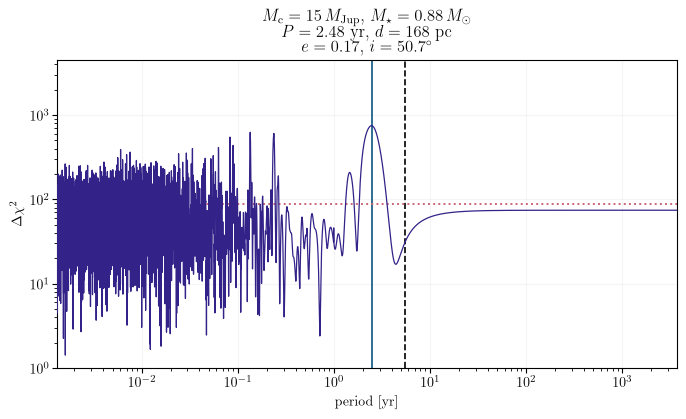

In [4]:
row = picks.iloc[0]
t, psi, pfac, y, yerr = pf.epochs_for_row(POP)(row)
periods, power = PGRAM(t, psi, pfac, y, yerr)
j = int(np.argmax(power))
print(f"{row['tag']}: {int(row['gaia_source_id'])}  {len(y)} epochs (table: {int(row['n_epochs'])})")
print(f"   re-run peak Delta-chi2 {power[j]:.3f} at {periods[j]:.4f} yr;  "
      f"table top_power {row['top_power']:.3f} at best_period {row['best_period']:.4f} yr")
assert np.isclose(power[j], row["top_power"], rtol=1e-6) and np.isclose(periods[j], row["best_period"], rtol=1e-9)

fig, ax = plt.subplots(figsize=(8, 4))
pf._draw_periodogram(ax, periods, power, row, pf.CLASS_COLORS[row["cls"]], thr_orbit, pf.BASELINE)
ax.set(xlabel="period [yr]", ylabel=r"$\Delta\chi^2$", title=pf._param_title(row))
plt.show()

## 3. The paper figure

The $\mathrm{SNR_{tot}}$ loci are the same as on Figure 7, drawn on the stars behind the map and
labelled as there: stacked in the empty upper-left corner with an arrow out to each curve, so the
boxes cover only the null class and stay clear of the nine badges.

  A   4655026950041457536  P =     2.479 yr  M =  15.326 MJup  narrow  (peak 747.8)


  B   6340070713349433856  P =     1.122 yr  M =   6.627 MJup  narrow  (peak 409.3)


  C    602247568446231936  P =     2.620 yr  M =  39.846 MJup  narrow  (peak 293.2)


  D   5480103189928118144  P =     7.066 yr  M =  11.783 MJup  broad  (peak 321.5)


  E   3415503442849782528  P =    25.198 yr  M =  33.215 MJup  broad  (peak 11362.6)


  F   1834795945671581824  P =   317.571 yr  M =  64.321 MJup  broad  (peak 24.7)


  G   3565648318330551296  P =     0.102 yr  M =   0.010 MJup  undet  (peak 11.3)


  H   5414321092869192704  P =     2.808 yr  M =   0.481 MJup  undet  (peak 30.0)


  I   2935095510956735232  P =   450.058 yr  M =  19.611 MJup  undet  (peak 18.7)


  wrote analysis/paper_figures/characterizability_examples_kepmodel_3class.pdf, analysis/paper_figures/characterizability_examples_kepmodel_3class.png


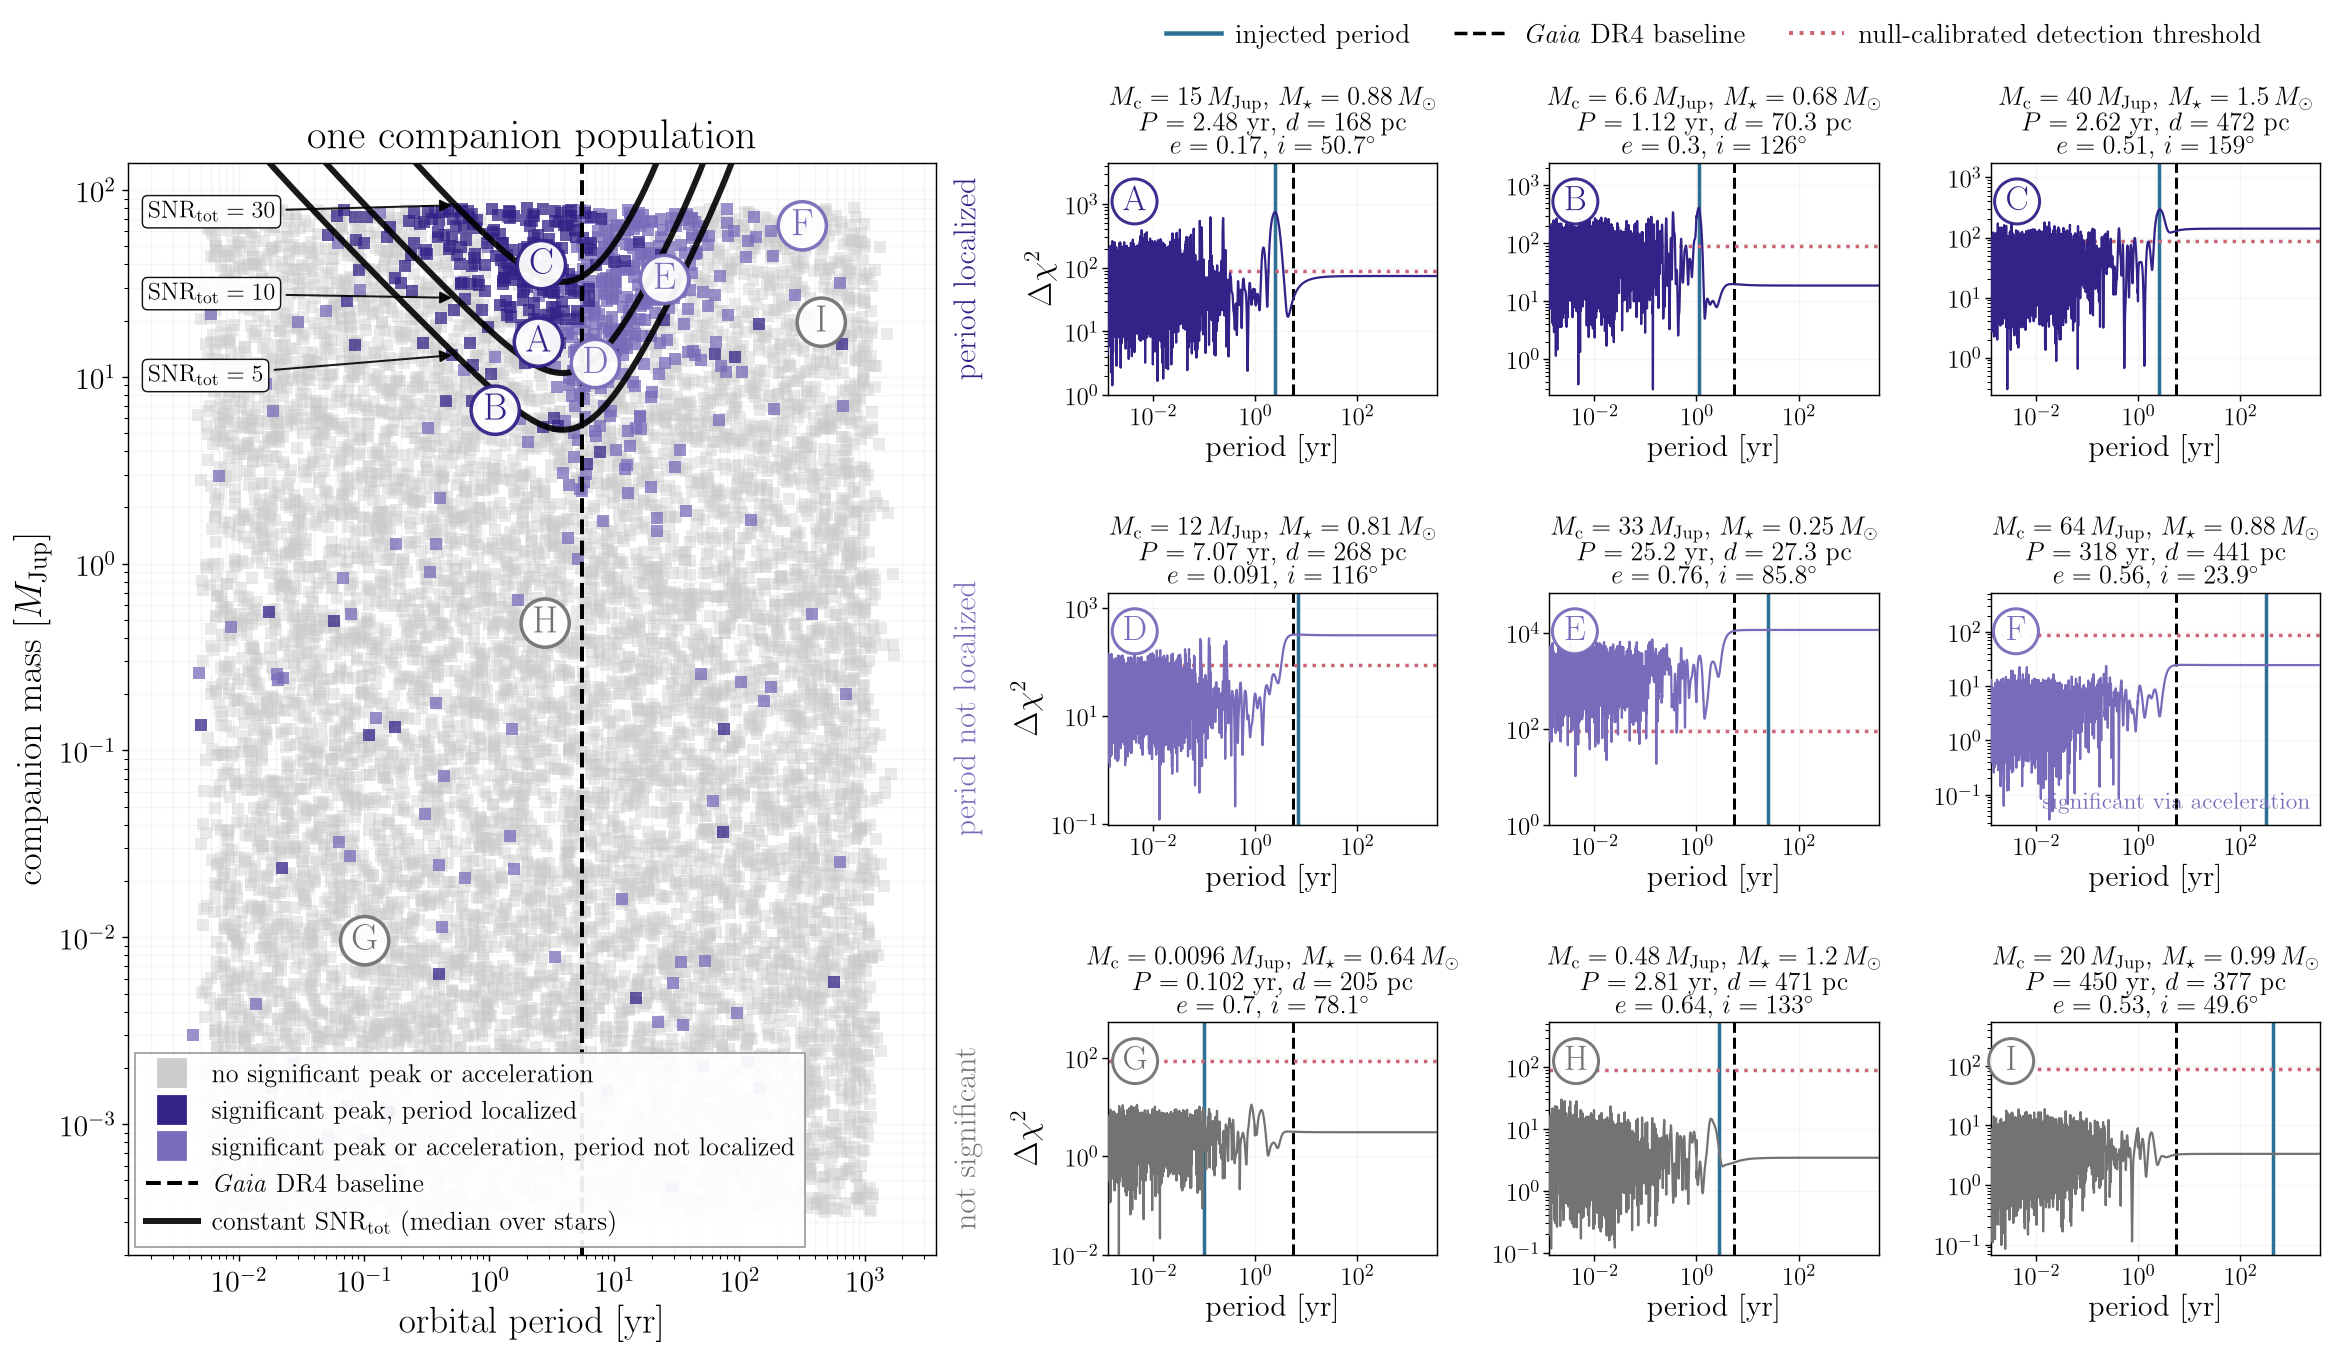

In [5]:
SNR_LINES = (5, 10, 30)
SNR_FONTSIZE = 13.5
SNR_CORNER, SNR_CORNER_DY, SNR_CORNER_ANCHOR = (0.025, 0.965), 0.075, 0.25
FIG_TAG = "_kepmodel_3class"

fig, picks = pf.examples(
    MAP_DRAW, "one companion population", classify=CLF, periodogram=PGRAM, epochs_for=pf.epochs_for_row(POP),
    ax_x=AX_P, ax_y=pf.AX_M, anchors=ANCHORS, thr_orbit=thr_orbit, baseline=pf.BASELINE,
    snr_lines=SNR_LINES, snr_fontsize=SNR_FONTSIZE, snr_mode=pf.SNR_LABEL_CORNER,
    snr_corner=SNR_CORNER, snr_corner_dy=SNR_CORNER_DY, snr_corner_anchor=SNR_CORNER_ANCHOR,
    stem="characterizability_examples", name_tag=FIG_TAG, paper=True)
plt.close(fig)
display(Image(filename=str(pf.PAPER_FIG_DIR / f"characterizability_examples{FIG_TAG}.png"), width=1100))